<a href="https://colab.research.google.com/github/hasan2733/artificial-intelligence/blob/main/Notebooks/Implementation/cleveland_dataset.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip install -q "flaml[automl]"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 223.6/223.6 MB 4.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 353.0/353.0 kB 31.1 MB/s eta 0:00:00


**Cell 2: Import**

In [ ]:
import warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import (train_test_split, GridSearchCV, StratifiedKFold,
                                     RepeatedStratifiedKFold, cross_val_score)
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, f1_score,
                             precision_score, recall_score, roc_auc_score,
                             average_precision_score, matthews_corrcoef,
                             confusion_matrix, roc_curve, precision_recall_curve,
                             classification_report)

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier
from sklearn.tree import DecisionTreeClassifier

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, Input
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
sns.set_style("whitegrid")

**Cell 3: CSV upload**

In [ ]:
from google.colab import files
uploaded = files.upload()
CSV_PATH = list(uploaded.keys())[0]
print("Loaded:", CSV_PATH)

Saving heart.csv to heart.csv
Loaded: heart.csv


In [ ]:
df = pd.read_csv(CSV_PATH)
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1025 entries, 0 to 1024
Data columns (total 14 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1025 non-null   int64  
 1   sex       1025 non-null   int64  
 2   cp        1025 non-null   int64  
 3   trestbps  1025 non-null   int64  
 4   chol      1025 non-null   int64  
 5   fbs       1025 non-null   int64  
 6   restecg   1025 non-null   int64  
 7   thalach   1025 non-null   int64  
 8   exang     1025 non-null   int64  
 9   oldpeak   1025 non-null   float64
 10  slope     1025 non-null   int64  
 11  ca        1025 non-null   int64  
 12  thal      1025 non-null   int64  
 13  target    1025 non-null   int64  
dtypes: float64(1), int64(13)
memory usage: 112.2 KB


In [ ]:
TARGET = "target"

print("Original shape :", df.shape)

n_dup = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicates removed: {n_dup}")
print("Shape after drop  :", df.shape)

# multi-class target hole binary kora
if df[TARGET].nunique() > 2:
    df[TARGET] = (df[TARGET] > 0).astype(int)

print("\nTarget distribution:\n", df[TARGET].value_counts())
print("\nMissing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("\nDtypes:\n", df.dtypes)
df.head()

Original shape : (1025, 14)
Duplicates removed: 723
Shape after drop  : (302, 14)

Target distribution:
 target
1    164
0    138
Name: count, dtype: int64

Missing values:
 Series([], dtype: int64)

Dtypes:
 age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64
dtype: object


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,52,1,0,125,212,0,1,168,0,1.0,2,2,3,0
1,53,1,0,140,203,1,0,155,1,3.1,0,0,3,0
2,70,1,0,145,174,0,1,125,1,2.6,0,0,3,0
3,61,1,0,148,203,0,1,161,0,0.0,2,1,3,0
4,62,0,0,138,294,1,1,106,0,1.9,1,3,2,0


**Cell 5: EDA visualization**

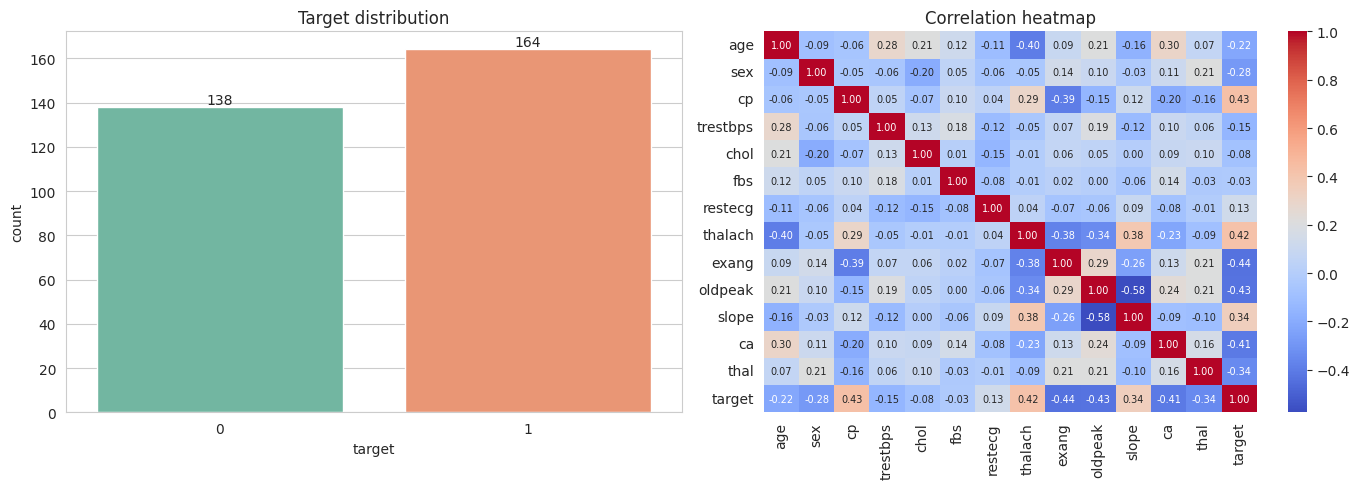

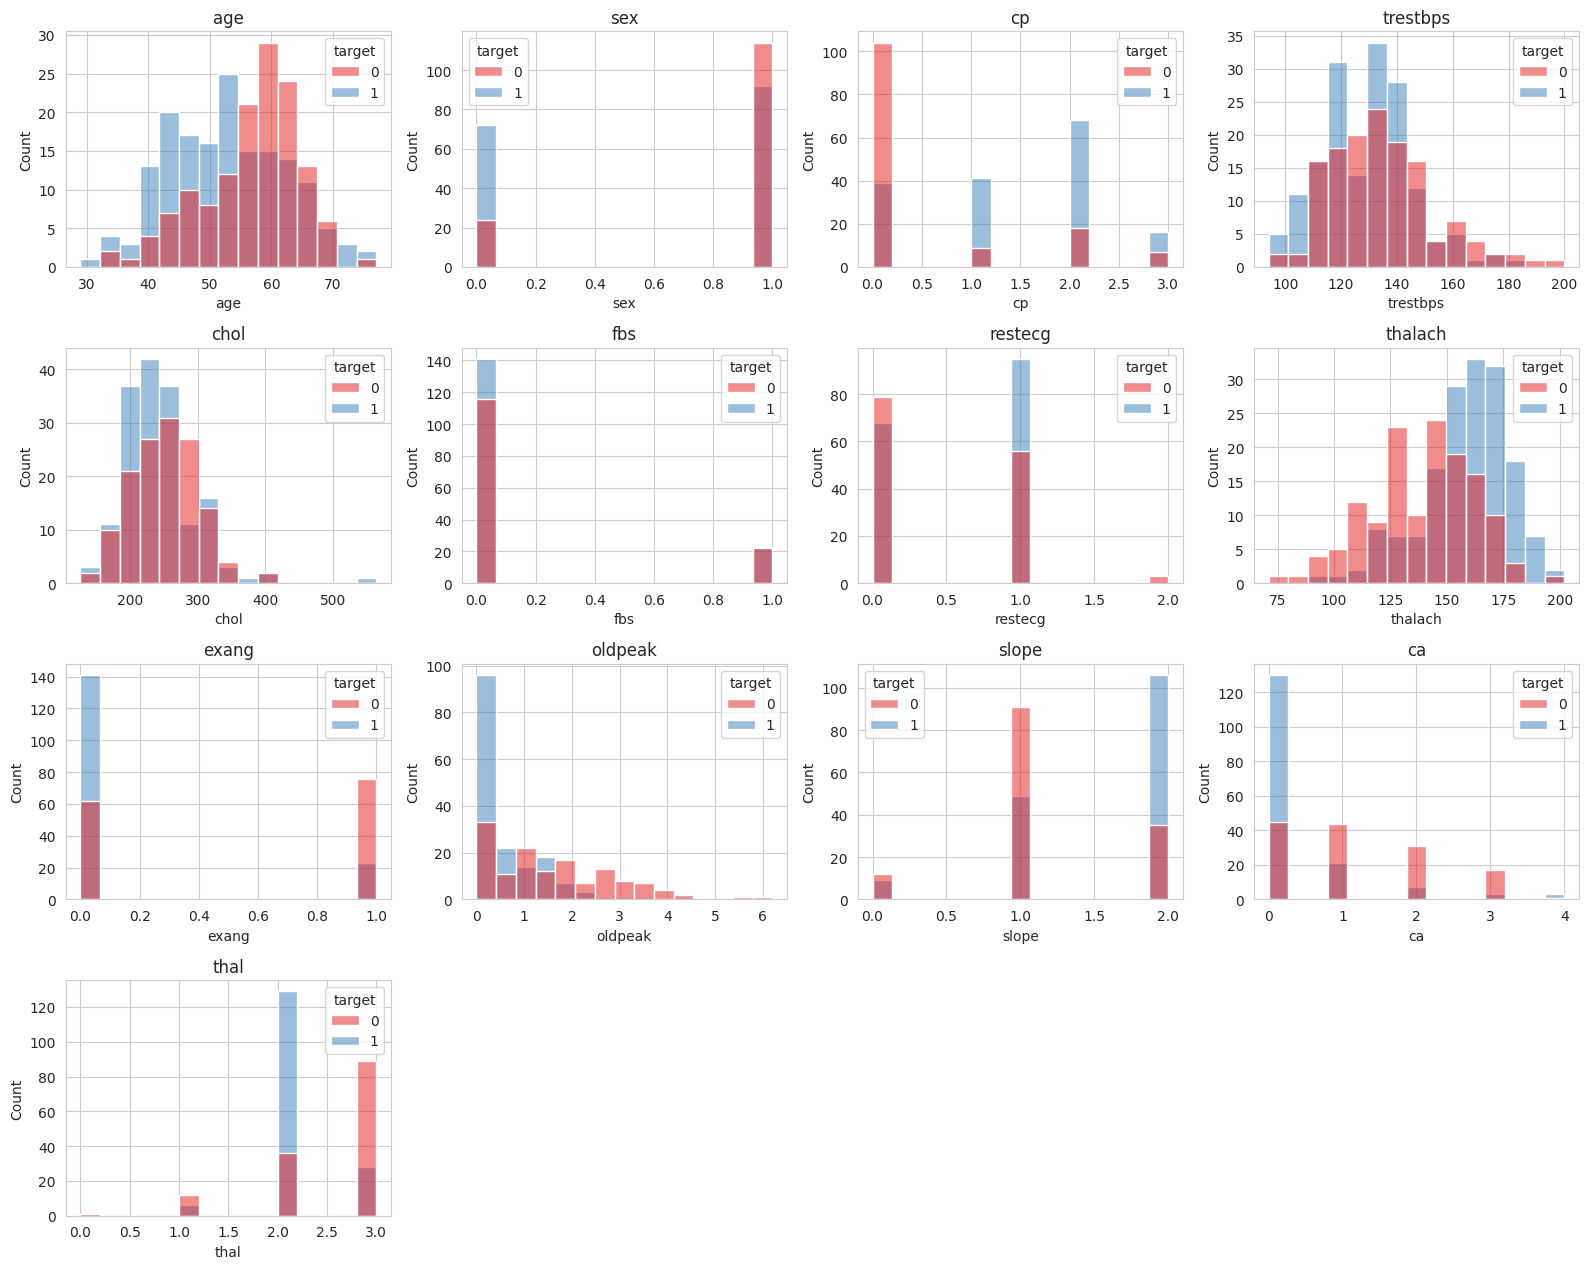

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))

# 1) Target distribution
sns.countplot(x=TARGET, data=df, ax=ax[0], palette="Set2")
ax[0].set_title("Target distribution")
for c in ax[0].containers:
    ax[0].bar_label(c)

# 2) Correlation heatmap
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=ax[1],
            annot_kws={"size": 7})
ax[1].set_title("Correlation heatmap")
plt.tight_layout()
plt.show()

# 3) Feature distribution by target
feat_cols = [c for c in df.columns if c != TARGET]
n = len(feat_cols)
ncols = 4
nrows = int(np.ceil(n / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(16, 3.2 * nrows))
for a, col in zip(axes.ravel(), feat_cols):
    sns.histplot(data=df, x=col, hue=TARGET, kde=False, ax=a, multiple="layer",
                 palette="Set1", bins=15)
    a.set_title(col)
for a in axes.ravel()[n:]:
    a.axis("off")
plt.tight_layout()
plt.show()

**Cell 6: Split + preprocessing**

In [ ]:
X = df.drop(columns=TARGET)
y = df[TARGET].astype(int)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y)
print("Train:", X_train.shape, " Test:", X_test.shape)

ONE_HOT = False

def make_pre(one_hot=None):
    one_hot = ONE_HOT if one_hot is None else one_hot
    if not one_hot:
        return StandardScaler()
    cat = [c for c in ["cp", "restecg", "slope", "thal"] if c in X.columns]
    num = [c for c in X.columns if c not in cat]
    return ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat),
        ("num", StandardScaler(), num)])

Train: (241, 13)  Test: (61, 13)


**Cell 7: Models + Grid (GridSearchCV + Stratified KFold)**

In [ ]:
MODELS = {
    "LogReg": (LogisticRegression(max_iter=5000),
               {"clf__C": [0.01, 0.1, 1, 10, 100],
                "clf__penalty": ["l1", "l2"],
                "clf__solver": ["liblinear"]}),

    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [3, 5, 7, 9, 11, 15, 21],
             "clf__weights": ["uniform", "distance"],
             "clf__p": [1, 2]}),

    "SVM": (SVC(probability=True, random_state=SEED),
            {"clf__C": [0.1, 1, 10, 100],
             "clf__kernel": ["rbf", "linear"],
             "clf__gamma": ["scale", 0.01, 0.1]}),

    "NaiveBayes": (GaussianNB(),
                   {"clf__var_smoothing": np.logspace(-9, -1, 9)}),

    "MLP": (MLPClassifier(max_iter=2000, random_state=SEED),
            {"clf__hidden_layer_sizes": [(32,), (64, 32), (128, 64, 32)],
             "clf__alpha": [1e-4, 1e-2, 1e-1],
             "clf__learning_rate_init": [1e-3, 1e-2]}),

    "GradBoost": (GradientBoostingClassifier(random_state=SEED),
                  {"clf__n_estimators": [50, 100, 200],
                   "clf__learning_rate": [0.03, 0.1],
                   "clf__max_depth": [1, 2, 3],
                   "clf__subsample": [0.7, 1.0]}),

    "AdaBoost": (AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=1),
                                    random_state=SEED),
                 {"clf__n_estimators": [50, 100, 200],
                  "clf__learning_rate": [0.01, 0.1, 0.5, 1.0],
                  "clf__estimator__max_depth": [1, 2]}),
}

inner_cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

best_models, test_preds, grid_rows = {}, {}, []
for name, (est, grid) in MODELS.items():
    t0 = time.time()
    pipe = Pipeline([("pre", make_pre()), ("clf", clone(est))])
    gs = GridSearchCV(pipe, grid, cv=inner_cv, scoring="accuracy",
                      n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)

    best_models[name] = gs.best_estimator_
    y_pred = gs.predict(X_test)
    y_proba = gs.predict_proba(X_test)[:, 1]
    test_preds[name] = (y_pred, y_proba)

    grid_rows.append({"model": name,
                      "grid_cv_acc": gs.best_score_,
                      "test_acc": accuracy_score(y_test, y_pred),
                      "best_params": gs.best_params_})
    print(f"{name:11s} grid-CV={gs.best_score_:.4f}  test={grid_rows[-1]['test_acc']:.4f}  ({time.time()-t0:.0f}s)")

grid_df = pd.DataFrame(grid_rows).sort_values("grid_cv_acc", ascending=False)
pd.set_option("display.max_colwidth", 120)
display(grid_df)

LogReg      grid-CV=0.8462  test=0.8033  (4s)
KNN         grid-CV=0.8545  test=0.8197  (2s)
SVM         grid-CV=0.8504  test=0.7705  (9s)
NaiveBayes  grid-CV=0.8213  test=0.8033  (0s)
MLP         grid-CV=0.8423  test=0.7705  (19s)
GradBoost   grid-CV=0.8464  test=0.7705  (20s)
AdaBoost    grid-CV=0.8505  test=0.7705  (32s)


,model,grid_cv_acc,test_acc,best_params
1,KNN,0.854507,0.819672,"{'clf__n_neighbors': 21, 'clf__p': 1, 'clf__weights': 'uniform'}"
6,AdaBoost,0.850510,0.770492,"{'clf__estimator__max_depth': 2, 'clf__learning_rate': 0.1, 'clf__n_estimators': 200}"
2,SVM,0.850425,0.770492,"{'clf__C': 1, 'clf__gamma': 'scale', 'clf__kernel': 'rbf'}"
5,GradBoost,0.846429,0.770492,"{'clf__learning_rate': 0.1, 'clf__max_depth': 2, 'clf__n_estimators': 50, 'clf__subsample': 1.0}"
0,LogReg,0.846173,0.803279,"{'clf__C': 0.01, 'clf__penalty': 'l2', 'clf__solver': 'liblinear'}"
4,MLP,0.842262,0.770492,"{'clf__alpha': 0.0001, 'clf__hidden_layer_sizes': (128, 64, 32), 'clf__learning_rate_init': 0.001}"
3,NaiveBayes,0.821259,0.803279,{'clf__var_smoothing': 0.1}


**Cell 8: Nested CV**

LogReg      nested acc = 0.8195 ± 0.0358  (5s)
KNN         nested acc = 0.8129 ± 0.0357  (10s)
SVM         nested acc = 0.8245 ± 0.0293  (102s)
NaiveBayes  nested acc = 0.8228 ± 0.0359  (3s)
MLP         nested acc = 0.7980 ± 0.0376  (336s)
GradBoost   nested acc = 0.8394 ± 0.0257  (195s)
AdaBoost    nested acc = 0.8343 ± 0.0371  (236s)


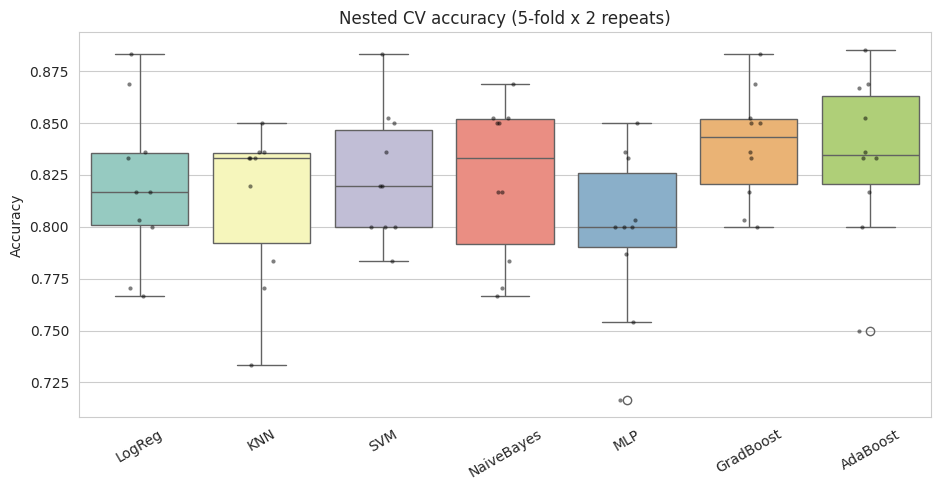

In [ ]:
outer_cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)

nested_scores = {}
for name, (est, grid) in MODELS.items():
    t0 = time.time()
    pipe = Pipeline([("pre", make_pre()), ("clf", clone(est))])
    gs = GridSearchCV(pipe, grid, cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                      scoring="accuracy", n_jobs=-1)
    nested_scores[name] = cross_val_score(gs, X, y, cv=outer_cv,
                                          scoring="accuracy", n_jobs=1)
    s = nested_scores[name]
    print(f"{name:11s} nested acc = {s.mean():.4f} ± {s.std():.4f}  ({time.time()-t0:.0f}s)")

nested_df = pd.DataFrame(nested_scores)
plt.figure(figsize=(11, 5))
sns.boxplot(data=nested_df, palette="Set3")
sns.stripplot(data=nested_df, color="black", size=3, alpha=0.5)
plt.title("Nested CV accuracy (5-fold x 2 repeats)")
plt.ylabel("Accuracy")
plt.xticks(rotation=30)
plt.show()

**Cell 9: AutoML (FLAML)**

In [ ]:
from flaml import AutoML

automl = AutoML()
automl.fit(X_train, y_train, task="classification", metric="accuracy",
           time_budget=120, eval_method="cv", n_splits=5, seed=SEED,
           estimator_list=["lgbm", "rf", "extra_tree", "xgboost", "lrl1"],
           verbose=0)

print("Best learner :", automl.best_estimator)
print("Best config  :", automl.best_config)
print("Best CV acc  :", 1 - automl.best_loss)

y_pred_a = automl.predict(X_test)
y_proba_a = automl.predict_proba(X_test)[:, 1]
test_preds["AutoML(FLAML)"] = (y_pred_a, y_proba_a)
print("Test acc     :", accuracy_score(y_test, y_pred_a))

INFO:flaml.tune.searcher.blendsearch:No low-cost partial config given to the search algorithm. For cost-frugal search, consider providing low-cost values for cost-related hps via 'low_cost_partial_config'. More info can be found at https://microsoft.github.io/FLAML/docs/FAQ#about-low_cost_partial_config-in-tune


Best learner : lgbm
Best config  : {'n_estimators': 75, 'num_leaves': 17, 'min_child_samples': 72, 'learning_rate': np.float64(0.066481510671801), 'log_max_bin': 4, 'colsample_bytree': np.float64(0.8284456153049575), 'reg_alpha': np.float64(0.03025756048704985), 'reg_lambda': np.float64(7.929884232212978)}
Best CV acc  : 0.8628401360544218
Test acc     : 0.7704918032786885


**Cell 10: Neural Network**

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,353 (63.88 KB)

 Trainable params: 16,353 (63.88 KB)

 Non-trainable params: 0 (0.00 B)

Epochs run: 216
NN test accuracy: 0.6229508196721312


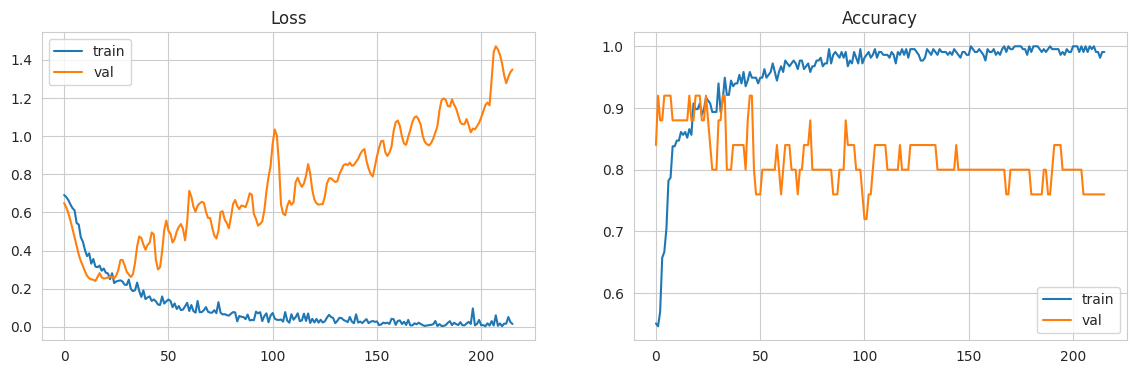

In [ ]:
Xtr = make_pre().fit(X_train)
Xtr_s, Xte_s = Xtr.transform(X_train), Xtr.transform(X_test)

def build_nn(input_dim):
    m = Sequential([
        Input(shape=(input_dim,)),
        Dense(128, activation="relu"), Dropout(0.2),
        Dense(64,  activation="relu"), Dropout(0.2),
        Dense(32,  activation="relu"), Dropout(0.2),
        Dense(64,  activation="relu"), Dropout(0.2),
        Dense(32,  activation="relu"), Dropout(0.2),
        Dense(1, activation="sigmoid"),
    ])
    m.compile(loss="binary_crossentropy", optimizer="adam", metrics=["accuracy"])
    return m

nn = build_nn(Xtr_s.shape[1])
nn.summary()

ckpt = ModelCheckpoint("best_model.keras", monitor="val_accuracy", mode="max",
                       save_best_only=True, verbose=0)

USE_EARLY_STOP = True   # somoy bachabe; False dile pura 2000 epoch cholbe
callbacks = [ckpt]
if USE_EARLY_STOP:
    callbacks.append(EarlyStopping(monitor="val_loss", patience=200, verbose=0))

history = nn.fit(Xtr_s, y_train, epochs=2000, batch_size=64,
                 validation_split=0.1, callbacks=callbacks, verbose=0)
print("Epochs run:", len(history.history["loss"]))

best_nn = tf.keras.models.load_model("best_model.keras")
y_proba_nn = best_nn.predict(Xte_s, verbose=0).ravel()
y_pred_nn = (y_proba_nn >= 0.5).astype(int)
test_preds["NeuralNet"] = (y_pred_nn, y_proba_nn)
print("NN test accuracy:", accuracy_score(y_test, y_pred_nn))

# Training curves
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(history.history["loss"], label="train")
ax[0].plot(history.history["val_loss"], label="val")
ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(history.history["accuracy"], label="train")
ax[1].plot(history.history["val_accuracy"], label="val")
ax[1].set_title("Accuracy"); ax[1].legend()
plt.show()

**Cell 11: NN 5-Fold CV (fair comparison)**

In [ ]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
nn_cv_scores = []
for fold, (tr, te) in enumerate(skf.split(X, y), 1):
    pre = make_pre()
    Xa = pre.fit_transform(X.iloc[tr]); Xb = pre.transform(X.iloc[te])
    m = build_nn(Xa.shape[1])
    es = EarlyStopping(monitor="val_loss", patience=40, restore_best_weights=True)
    m.fit(Xa, y.iloc[tr], epochs=400, batch_size=64, validation_split=0.1,
          callbacks=[es], verbose=0)
    p = (m.predict(Xb, verbose=0).ravel() >= 0.5).astype(int)
    acc = accuracy_score(y.iloc[te], p)
    nn_cv_scores.append(acc)
    print(f"Fold {fold}: {acc:.4f}")

nn_cv_scores = np.array(nn_cv_scores)
print(f"\nNN 5-fold CV: {nn_cv_scores.mean():.4f} ± {nn_cv_scores.std():.4f}")

Fold 1: 0.8525


Fold 2: 0.8197
Fold 3: 0.8167
Fold 4: 0.8833
Fold 5: 0.8167

NN 5-fold CV: 0.8378 ± 0.0265


**Cell 12: Final evaluation table**

In [ ]:
def compute_metrics(y_true, y_pred, y_proba):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Acc": balanced_accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred),
        "Sensitivity": recall_score(y_true, y_pred),
        "Specificity": tn / (tn + fp),
        "F1": f1_score(y_true, y_pred),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "PR-AUC": average_precision_score(y_true, y_proba),
        "MCC": matthews_corrcoef(y_true, y_pred),
        "TN": tn, "FP": fp, "FN": fn, "TP": tp,
    }

rows = {n: compute_metrics(y_test, p, pr) for n, (p, pr) in test_preds.items()}
results = pd.DataFrame(rows).T.sort_values("Accuracy", ascending=False)

# Nested CV / NN CV score add kora
cv_mean = {n: s.mean() for n, s in nested_scores.items()}
cv_std = {n: s.std() for n, s in nested_scores.items()}
cv_mean["NeuralNet"], cv_std["NeuralNet"] = nn_cv_scores.mean(), nn_cv_scores.std()
results["CV Acc (mean)"] = pd.Series(cv_mean)
results["CV Acc (std)"] = pd.Series(cv_std)

metric_cols = ["Accuracy", "Balanced Acc", "Precision", "Sensitivity",
               "Specificity", "F1", "ROC-AUC", "PR-AUC", "MCC"]
display(results[metric_cols + ["CV Acc (mean)", "CV Acc (std)"]].round(4))
results.to_csv("final_results.csv")

,Accuracy,Balanced Acc,Precision,Sensitivity,Specificity,F1,ROC-AUC,PR-AUC,MCC,CV Acc (mean),CV Acc (std)
KNN,0.8197,0.8171,0.8235,0.8485,0.7857,0.8358,0.8945,0.8974,0.6363,0.8129,0.0357
LogReg,0.8033,0.7992,0.8000,0.8485,0.7500,0.8235,0.8810,0.9007,0.6031,0.8195,0.0358
NaiveBayes,0.8033,0.8047,0.8387,0.7879,0.8214,0.8125,0.8874,0.8978,0.6073,0.8228,0.0359
SVM,0.7705,0.7662,0.7714,0.8182,0.7143,0.7941,0.8420,0.8432,0.5365,0.8245,0.0293
MLP,0.7705,0.7689,0.7879,0.7879,0.7500,0.7879,0.8431,0.8359,0.5379,0.7980,0.0376
GradBoost,0.7705,0.7662,0.7714,0.8182,0.7143,0.7941,0.8658,0.8890,0.5365,0.8394,0.0257
AdaBoost,0.7705,0.7689,0.7879,0.7879,0.7500,0.7879,0.8387,0.8493,0.5379,0.8343,0.0371
AutoML(FLAML),0.7705,0.7662,0.7714,0.8182,0.7143,0.7941,0.8864,0.9036,0.5365,NaN,NaN
NeuralNet,0.6230,0.5974,0.6000,0.9091,0.2857,0.7229,0.7684,0.8102,0.2525,0.8378,0.0265


**Cell 13: Metric comparison charts**

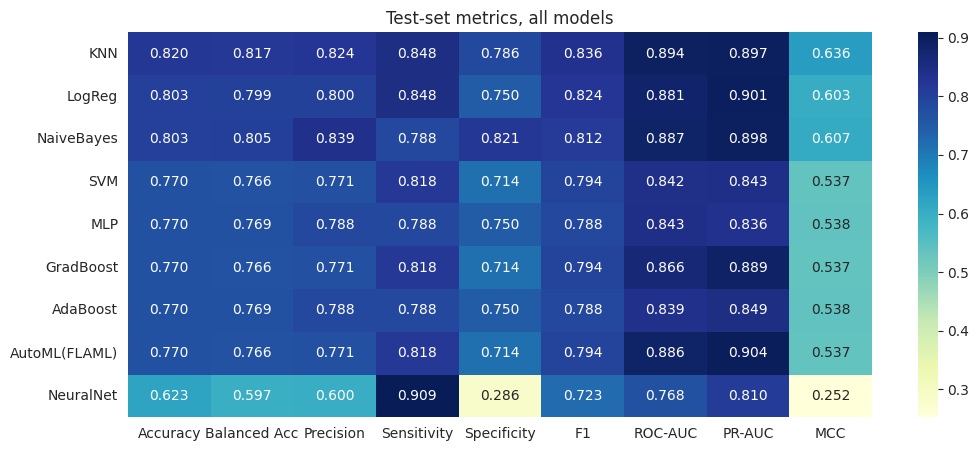

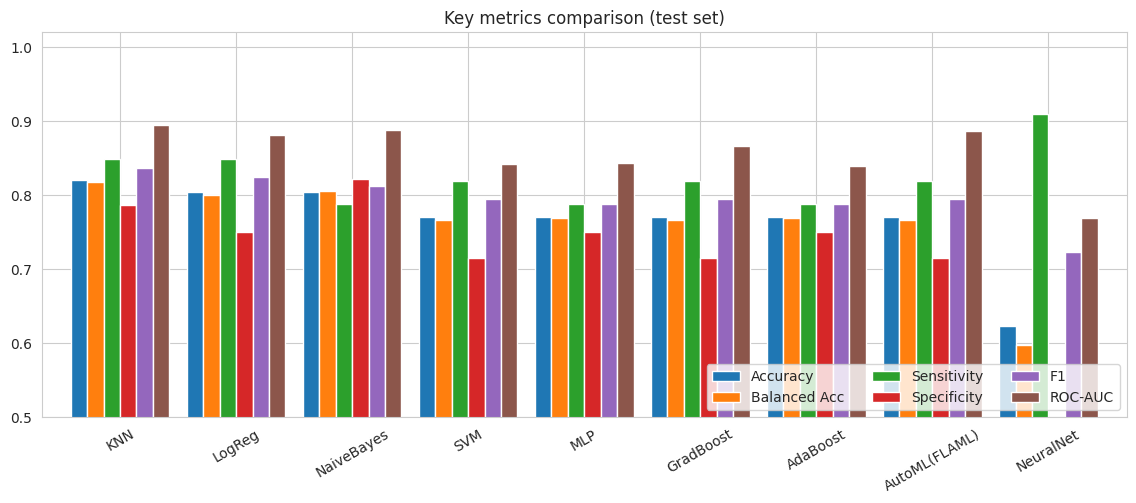

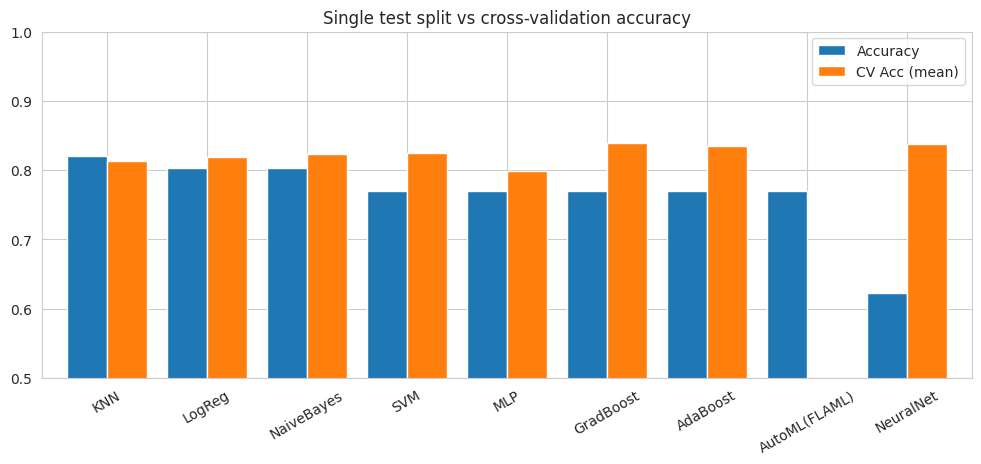

In [ ]:
# 1) Heatmap
plt.figure(figsize=(12, 5))
sns.heatmap(results[metric_cols].astype(float), annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("Test-set metrics, all models")
plt.show()

# 2) Grouped bar: key metrics
key = ["Accuracy", "Balanced Acc", "Sensitivity", "Specificity", "F1", "ROC-AUC"]
results[key].astype(float).plot(kind="bar", figsize=(14, 5), width=0.85)
plt.ylim(0.5, 1.02)
plt.title("Key metrics comparison (test set)")
plt.xticks(rotation=30)
plt.legend(loc="lower right", ncol=3)
plt.show()

# 3) Test acc vs CV acc (single split vs stable estimate)
cmp = results[["Accuracy", "CV Acc (mean)"]].astype(float)
ax = cmp.plot(kind="bar", figsize=(12, 4.5), width=0.8)
plt.ylim(0.5, 1.0)
plt.title("Single test split vs cross-validation accuracy")
plt.xticks(rotation=30)
plt.show()

**Cell 14: Confusion matrices**

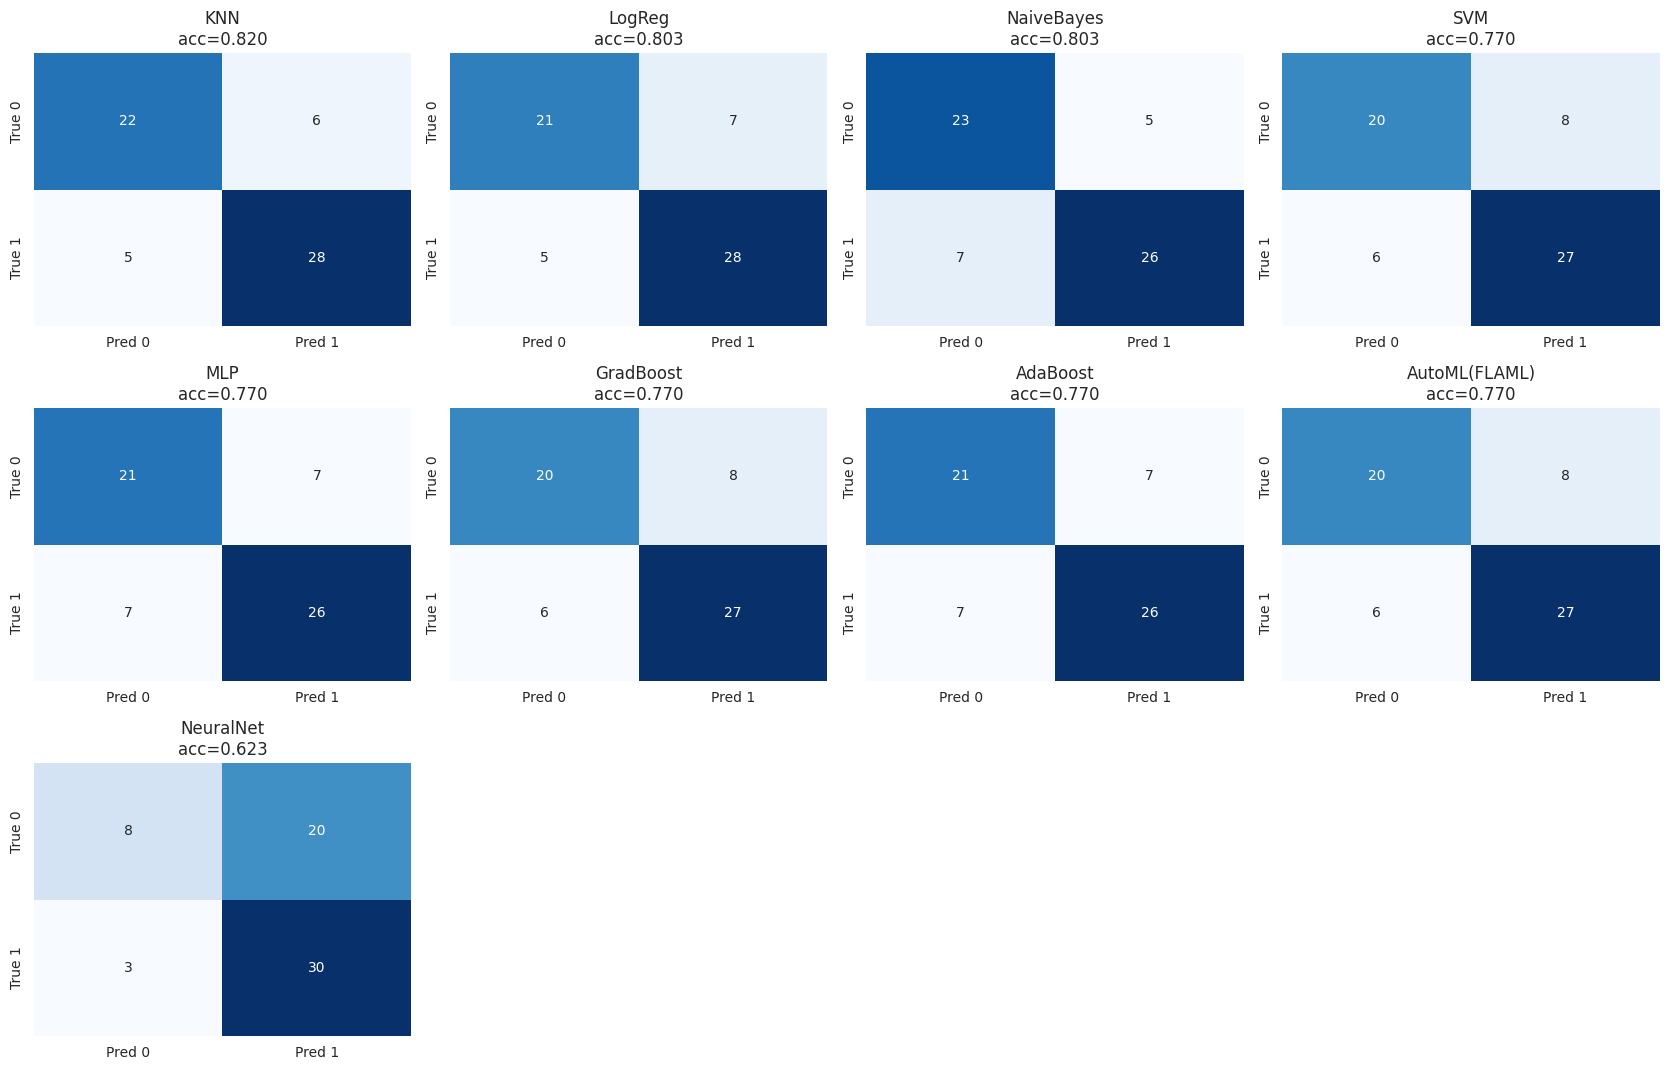

In [ ]:
names = list(results.index)
ncols = 4
nrows = int(np.ceil(len(names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.6 * nrows))
for ax, n in zip(axes.ravel(), names):
    p, _ = test_preds[n]
    cm = confusion_matrix(y_test, p, labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
    ax.set_title(f"{n}\nacc={accuracy_score(y_test, p):.3f}")
for ax in axes.ravel()[len(names):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

**Cell 15: ROC and Precision-Recall curve**

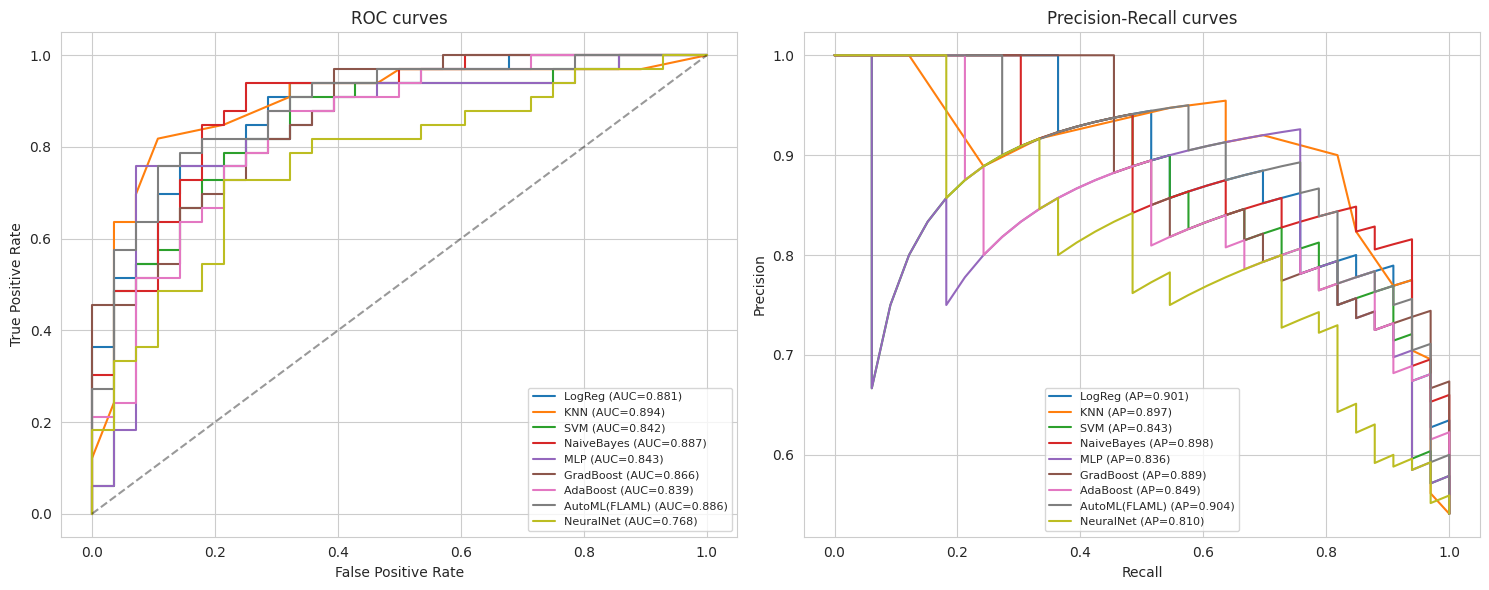

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(15, 6))
for n, (p, pr) in test_preds.items():
    fpr, tpr, _ = roc_curve(y_test, pr)
    ax[0].plot(fpr, tpr, label=f"{n} (AUC={roc_auc_score(y_test, pr):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, pr)
    ax[1].plot(rec, prec, label=f"{n} (AP={average_precision_score(y_test, pr):.3f})")

ax[0].plot([0, 1], [0, 1], "k--", alpha=0.4)
ax[0].set_xlabel("False Positive Rate"); ax[0].set_ylabel("True Positive Rate")
ax[0].set_title("ROC curves"); ax[0].legend(fontsize=8)
ax[1].set_xlabel("Recall"); ax[1].set_ylabel("Precision")
ax[1].set_title("Precision-Recall curves"); ax[1].legend(fontsize=8)
plt.tight_layout()
plt.show()

**Cell 16: Best model detail report + feature importance**

Best by CV accuracy : GradBoost
Best by test accuracy: KNN 

Classification report (GradBoost):

              precision    recall  f1-score   support

  No disease       0.77      0.71      0.74        28
     Disease       0.77      0.82      0.79        33

    accuracy                           0.77        61
   macro avg       0.77      0.77      0.77        61
weighted avg       0.77      0.77      0.77        61



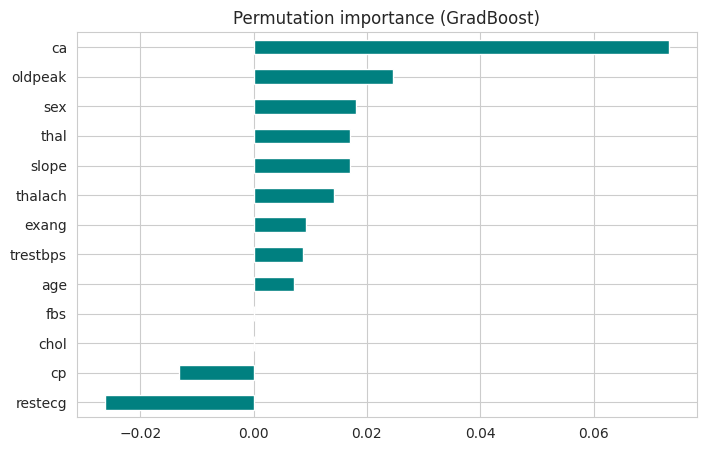

In [ ]:
best_name = results["CV Acc (mean)"].astype(float).idxmax()
print("Best by CV accuracy :", best_name)
print("Best by test accuracy:", results["Accuracy"].astype(float).idxmax(), "\n")

p, _ = test_preds[best_name]
print(f"Classification report ({best_name}):\n")
print(classification_report(y_test, p, target_names=["No disease", "Disease"]))

# Permutation importance (sklearn pipeline model hole)
if best_name in best_models:
    from sklearn.inspection import permutation_importance
    r = permutation_importance(best_models[best_name], X_test, y_test,
                               n_repeats=30, random_state=SEED, scoring="accuracy")
    imp = pd.Series(r.importances_mean, index=X.columns).sort_values()
    imp.plot(kind="barh", figsize=(8, 5), color="teal")
    plt.title(f"Permutation importance ({best_name})")
    plt.show()

**Cell A: Outlier detect + visualization (IQR method)**

Bounds:
  age       [   28.50,    80.50]  outliers = 0
  trestbps  [   90.00,   170.00]  outliers = 9
  chol      [  115.38,   370.38]  outliers = 5
  thalach   [   84.12,   215.12]  outliers = 1
  oldpeak   [   -2.40,     4.00]  outliers = 5

Total outlier rows: 19 / 302
Outlier rows-er target distribution:
 target
0    13
1     6
Name: count, dtype: int64


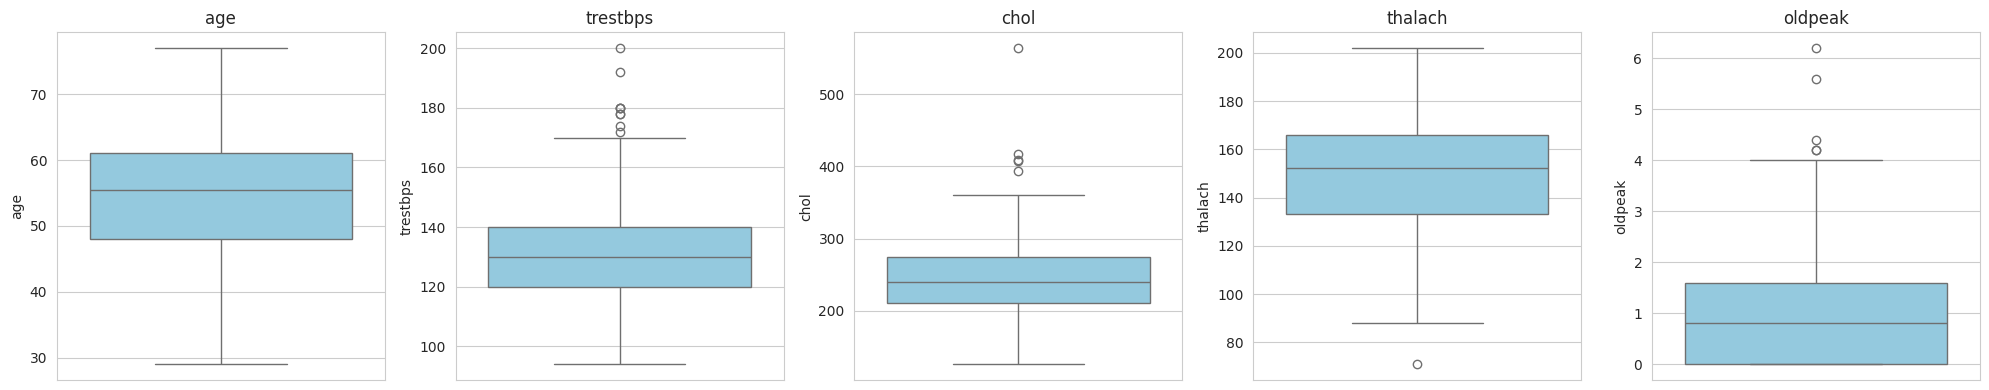

In [ ]:
IQR_K = 1.5
OUT_COLS = [c for c in ["age", "trestbps", "chol", "thalach", "oldpeak"] if c in df.columns]

def iqr_bounds(frame, cols, k=IQR_K):
    b = {}
    for c in cols:
        q1, q3 = frame[c].quantile([0.25, 0.75])
        iqr = q3 - q1
        b[c] = (q1 - k * iqr, q3 + k * iqr)
    return b

def outlier_mask(frame, bounds):
    """True = outlier row (kono ekta column-e bound-er baire)"""
    m = pd.Series(False, index=frame.index)
    for c, (lo, hi) in bounds.items():
        m |= (frame[c] < lo) | (frame[c] > hi)
    return m

bounds_all = iqr_bounds(df, OUT_COLS)
mask_all = outlier_mask(df, bounds_all)

print("Bounds:")
for c, (lo, hi) in bounds_all.items():
    n = ((df[c] < lo) | (df[c] > hi)).sum()
    print(f"  {c:9s} [{lo:8.2f}, {hi:8.2f}]  outliers = {n}")
print(f"\nTotal outlier rows: {mask_all.sum()} / {len(df)}")
print("Outlier rows-er target distribution:\n", df.loc[mask_all, TARGET].value_counts())

fig, axes = plt.subplots(1, len(OUT_COLS), figsize=(4 * len(OUT_COLS), 4))
for ax, c in zip(np.atleast_1d(axes), OUT_COLS):
    sns.boxplot(y=df[c], ax=ax, color="skyblue")
    ax.set_title(c)
plt.tight_layout()
plt.show()

**Cell B: Outlier drop**

In [ ]:
df_clean = df[~mask_all].reset_index(drop=True)
print("Before:", df.shape, " After:", df_clean.shape)
print("\nTarget distribution (before):\n", df[TARGET].value_counts())
print("\nTarget distribution (after):\n", df_clean[TARGET].value_counts())

Before: (302, 14)  After: (283, 14)

Target distribution (before):
 target
1    164
0    138
Name: count, dtype: int64

Target distribution (after):
 target
1    158
0    125
Name: count, dtype: int64


**Cell C:**

In [ ]:
REMOVE_OUTLIERS = True      # False means with outlier

df_used = df_clean if REMOVE_OUTLIERS else df
X = df_used.drop(columns=TARGET)
y = df_used[TARGET].astype(int)
print("Using dataset:", X.shape, "| outliers removed:", REMOVE_OUTLIERS)

Using dataset: (283, 13) | outliers removed: True


In [ ]:
X_all = df.drop(columns=TARGET)
y_all = df[TARGET].astype(int)

cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

def cv_with_optional_outlier_drop(model, drop_outliers):
    accs, f1s, sens, aucs = [], [], [], []
    for tr, te in cv.split(X_all, y_all):
        Xtr, ytr = X_all.iloc[tr], y_all.iloc[tr]
        Xte, yte = X_all.iloc[te], y_all.iloc[te]
        if drop_outliers:
            b = iqr_bounds(Xtr, OUT_COLS)
            keep = ~outlier_mask(Xtr, b)
            Xtr, ytr = Xtr[keep], ytr[keep]
        m = clone(model).fit(Xtr, ytr)
        p = m.predict(Xte)
        accs.append(accuracy_score(yte, p))
        f1s.append(f1_score(yte, p))
        sens.append(recall_score(yte, p))
        aucs.append(roc_auc_score(yte, m.predict_proba(Xte)[:, 1]))
    return np.mean(accs), np.std(accs), np.mean(f1s), np.mean(sens), np.mean(aucs)

rows = []
for name, model in best_models.items():
    a0 = cv_with_optional_outlier_drop(model, False)
    a1 = cv_with_optional_outlier_drop(model, True)
    rows.append({"model": name,
                 "acc_keep": a0[0], "std_keep": a0[1],
                 "acc_drop": a1[0], "std_drop": a1[1],
                 "diff": a1[0] - a0[0],
                 "f1_keep": a0[2], "f1_drop": a1[2],
                 "sens_keep": a0[3], "sens_drop": a1[3],
                 "auc_keep": a0[4], "auc_drop": a1[4]})
    print(f"{name:11s} keep={a0[0]:.4f}  drop={a1[0]:.4f}  diff={a1[0]-a0[0]:+.4f}")

out_cmp = pd.DataFrame(rows).set_index("model")
display(out_cmp.round(4))

LogReg      keep=0.8245  drop=0.8267  diff=+0.0023
KNN         keep=0.8257  drop=0.8257  diff=+0.0000
SVM         keep=0.8223  drop=0.8267  diff=+0.0044
NaiveBayes  keep=0.8144  drop=0.8156  diff=+0.0011
MLP         keep=0.8013  drop=0.7902  diff=-0.0111
GradBoost   keep=0.8168  drop=0.8100  diff=-0.0068
AdaBoost    keep=0.8135  drop=0.8123  diff=-0.0011


,acc_keep,std_keep,acc_drop,std_drop,diff,f1_keep,f1_drop,sens_keep,sens_drop,auc_keep,auc_drop
model,,,,,,,,,,,
LogReg,0.8245,0.0328,0.8267,0.0313,0.0023,0.8467,0.8448,0.8923,0.8720,0.9084,0.9084
KNN,0.8257,0.0194,0.8257,0.0225,0.0000,0.8487,0.8503,0.9024,0.9146,0.9164,0.9147
SVM,0.8223,0.0265,0.8267,0.0343,0.0044,0.8424,0.8462,0.8782,0.8802,0.9002,0.8953
NaiveBayes,0.8144,0.0394,0.8156,0.0329,0.0011,0.8328,0.8335,0.8579,0.8557,0.8969,0.8987
MLP,0.8013,0.0408,0.7902,0.0420,-0.0111,0.8167,0.8067,0.8229,0.8107,0.8764,0.8705
GradBoost,0.8168,0.0235,0.8100,0.0321,-0.0068,0.8351,0.8258,0.8577,0.8353,0.8989,0.9033
AdaBoost,0.8135,0.0299,0.8123,0.0269,-0.0011,0.8303,0.8293,0.8496,0.8455,0.8927,0.8963


**Cell E: Comparison chart**

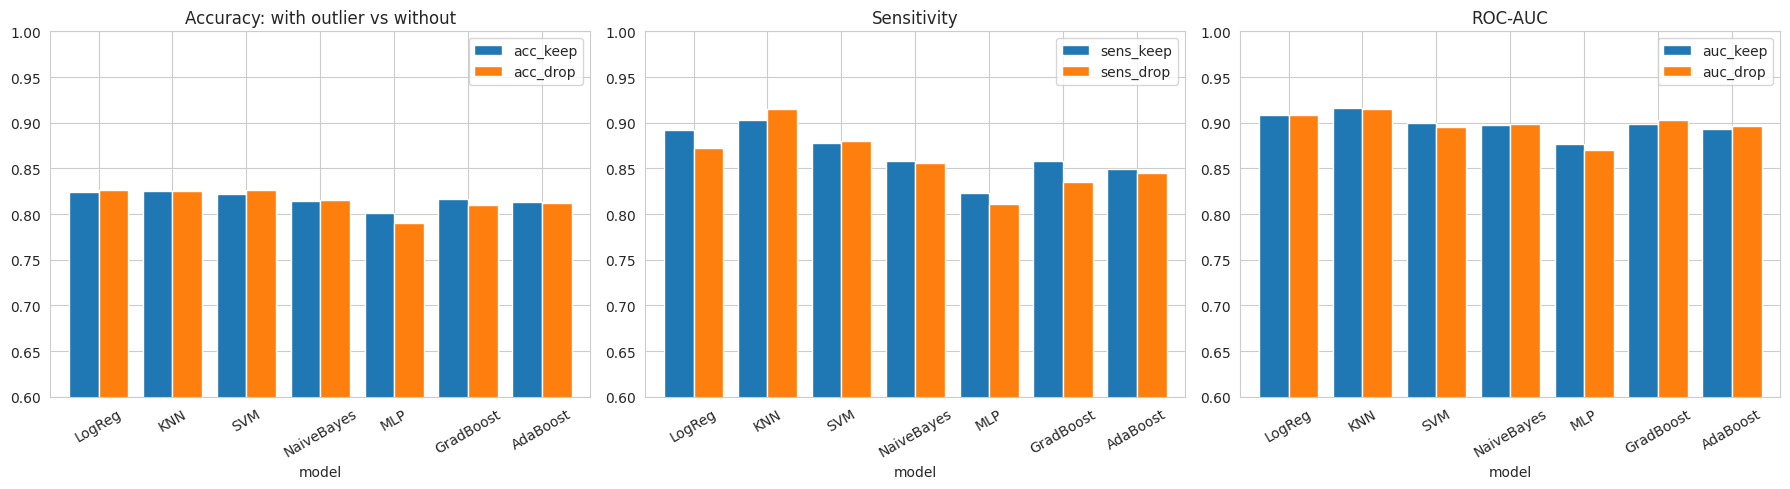

Mean diff: -0.0016
Only models with a difference greater than std_keep are considered to have meaningful changes.


In [ ]:
fig, ax = plt.subplots(1, 3, figsize=(18, 5))

out_cmp[["acc_keep", "acc_drop"]].plot(kind="bar", ax=ax[0], width=0.8)
ax[0].set_title("Accuracy: with outlier vs without")
ax[0].set_ylim(0.6, 1.0); ax[0].tick_params(axis="x", rotation=30)

out_cmp[["sens_keep", "sens_drop"]].plot(kind="bar", ax=ax[1], width=0.8)
ax[1].set_title("Sensitivity")
ax[1].set_ylim(0.6, 1.0); ax[1].tick_params(axis="x", rotation=30)

out_cmp[["auc_keep", "auc_drop"]].plot(kind="bar", ax=ax[2], width=0.8)
ax[2].set_title("ROC-AUC")
ax[2].set_ylim(0.6, 1.0); ax[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print("Mean diff:", out_cmp["diff"].mean().round(4))
print("Only models with a difference greater than std_keep are considered to have meaningful changes.")

**Cell E1: Imports**

In [ ]:
from sklearn.ensemble import (VotingClassifier, StackingClassifier, BaggingClassifier,
                              RandomForestClassifier, ExtraTreesClassifier,
                              HistGradientBoostingClassifier)
from sklearn.model_selection import cross_validate
from sklearn.metrics import make_scorer

**Cell E2: Choose base learners**

In [ ]:
BASE_NAMES = ["LogReg", "KNN", "SVM", "NaiveBayes", "MLP", "GradBoost", "AdaBoost"]

def fresh(name):
    return clone(best_models[name])

def base_estimators():
    return [(n, fresh(n)) for n in BASE_NAMES]

# Weights for weighted soft voting: better grid-CV accuracy gets more weight
acc = grid_df.set_index("model").loc[BASE_NAMES, "grid_cv_acc"]
W = list(((acc - 0.5).clip(lower=0.01) / (acc - 0.5).clip(lower=0.01).sum()).round(3))
print(dict(zip(BASE_NAMES, W)))

{'LogReg': 0.144, 'KNN': 0.147, 'SVM': 0.145, 'NaiveBayes': 0.133, 'MLP': 0.142, 'GradBoost': 0.144, 'AdaBoost': 0.145}


**Cell E3: Define all ensembles**

In [ ]:
skf5 = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

ENSEMBLES = {
    "Voting_Hard": VotingClassifier(base_estimators(), voting="hard"),
    "Voting_Soft": VotingClassifier(base_estimators(), voting="soft"),
    "Voting_SoftWeighted": VotingClassifier(base_estimators(), voting="soft", weights=W),

    # Stacking: meta-model learns from out-of-fold predictions (cv=5), so no in-sample leakage
    "Stacking_LR": StackingClassifier(
        base_estimators(), final_estimator=LogisticRegression(C=1.0, max_iter=2000),
        cv=skf5, stack_method="predict_proba"),
    "Stacking_GB": StackingClassifier(
        base_estimators(),
        final_estimator=GradientBoostingClassifier(n_estimators=50, max_depth=2,
                                                   learning_rate=0.05, random_state=SEED),
        cv=skf5, stack_method="predict_proba"),

    # Bagging of high-variance base models
    "Bagging_SVM": BaggingClassifier(
        estimator=Pipeline([("pre", make_pre()), ("clf", SVC(C=1, probability=True,
                                                             random_state=SEED))]),
        n_estimators=50, max_samples=0.8, random_state=SEED),
    "Bagging_KNN": BaggingClassifier(
        estimator=Pipeline([("pre", make_pre()), ("clf", KNeighborsClassifier(n_neighbors=9))]),
        n_estimators=50, max_samples=0.8, random_state=SEED),

    # Tree-ensemble baselines
    "RandomForest": RandomForestClassifier(n_estimators=400, max_depth=5, min_samples_leaf=2,
                                           random_state=SEED),
    "ExtraTrees": ExtraTreesClassifier(n_estimators=400, max_depth=5, min_samples_leaf=2,
                                       random_state=SEED),
    "HistGB": HistGradientBoostingClassifier(max_depth=3, learning_rate=0.05,
                                             max_iter=150, l2_regularization=1.0,
                                             random_state=SEED),
}
print(list(ENSEMBLES.keys()))

['Voting_Hard', 'Voting_Soft', 'Voting_SoftWeighted', 'Stacking_LR', 'Stacking_GB', 'Bagging_SVM', 'Bagging_KNN', 'RandomForest', 'ExtraTrees', 'HistGB']


**Cell E4: Fit on train, predict on the test split**

In [ ]:
fitted_ens = {}
for name, model in ENSEMBLES.items():
    t0 = time.time()
    model.fit(X_train, y_train)
    fitted_ens[name] = model

    y_pred = model.predict(X_test)
    if name == "Voting_Hard":
        votes = np.column_stack([m.predict(X_test) for m in model.estimators_])
        y_proba = votes.mean(axis=1)
    else:
        y_proba = model.predict_proba(X_test)[:, 1]

    test_preds[name] = (y_pred, y_proba)
    print(f"{name:20s} test acc = {accuracy_score(y_test, y_pred):.4f}  ({time.time()-t0:.0f}s)")

Voting_Hard          test acc = 0.7869  (2s)
Voting_Soft          test acc = 0.7869  (3s)
Voting_SoftWeighted  test acc = 0.7869  (5s)
Stacking_LR          test acc = 0.7869  (11s)
Stacking_GB          test acc = 0.7541  (6s)
Bagging_SVM          test acc = 0.7869  (0s)
Bagging_KNN          test acc = 0.8033  (0s)
RandomForest         test acc = 0.7705  (1s)
ExtraTrees           test acc = 0.7541  (1s)
HistGB               test acc = 0.7213  (0s)


**Cell E5: Fair CV comparison (base models vs ensembles, same folds)**

In [ ]:
cv_eval = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)

def specificity(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred, labels=[0, 1]).ravel()
    return tn / (tn + fp)

SCORING_FULL = {
    "Accuracy": "accuracy", "Balanced Acc": "balanced_accuracy",
    "Precision": "precision", "Sensitivity": "recall", "F1": "f1",
    "Specificity": make_scorer(specificity),
    "MCC": make_scorer(matthews_corrcoef),
    "ROC-AUC": "roc_auc", "PR-AUC": "average_precision",
}
SCORING_NOPROBA = {k: v for k, v in SCORING_FULL.items() if k not in ("ROC-AUC", "PR-AUC")}

models_to_cv = {f"[base] {n}": best_models[n] for n in BASE_NAMES}
models_to_cv.update({n: m for n, m in ENSEMBLES.items()})

cv_rows = {}
for name, model in models_to_cv.items():
    t0 = time.time()
    sc = SCORING_NOPROBA if name == "Voting_Hard" else SCORING_FULL
    out = cross_validate(clone(model), X, y, cv=cv_eval, scoring=sc, n_jobs=-1)
    row = {k: out[f"test_{k}"].mean() for k in sc}
    row["Acc std"] = out["test_Accuracy"].std()
    cv_rows[name] = row
    print(f"{name:22s} acc = {row['Accuracy']:.4f} ± {row['Acc std']:.4f}  ({time.time()-t0:.0f}s)")

cv_table = pd.DataFrame(cv_rows).T.sort_values("Accuracy", ascending=False)
display(cv_table.round(4))
cv_table.to_csv("ensemble_cv_results.csv")

[base] LogReg          acc = 0.8316 ± 0.0559  (3s)
[base] KNN             acc = 0.8269 ± 0.0436  (1s)
[base] SVM             acc = 0.8269 ± 0.0380  (1s)
[base] NaiveBayes      acc = 0.8185 ± 0.0521  (0s)
[base] MLP             acc = 0.7985 ± 0.0366  (10s)
[base] GradBoost       acc = 0.8316 ± 0.0556  (1s)
[base] AdaBoost        acc = 0.8304 ± 0.0534  (10s)
Voting_Hard            acc = 0.8469 ± 0.0496  (19s)
Voting_Soft            acc = 0.8351 ± 0.0410  (26s)
Voting_SoftWeighted    acc = 0.8339 ± 0.0421  (21s)
Stacking_LR            acc = 0.8410 ± 0.0491  (90s)
Stacking_GB            acc = 0.8151 ± 0.0594  (66s)
Bagging_SVM            acc = 0.8374 ± 0.0433  (7s)
Bagging_KNN            acc = 0.8257 ± 0.0377  (4s)
RandomForest           acc = 0.8351 ± 0.0550  (9s)
ExtraTrees             acc = 0.8375 ± 0.0476  (7s)
HistGB                 acc = 0.8244 ± 0.0645  (1s)


,Accuracy,Balanced Acc,Precision,Sensitivity,F1,Specificity,MCC,ROC-AUC,PR-AUC,Acc std
Voting_Hard,0.8469,0.8381,0.8349,0.9134,0.8696,0.7627,0.6960,NaN,NaN,0.0496
Stacking_LR,0.8410,0.8339,0.8378,0.8945,0.8620,0.7733,0.6839,0.9160,0.9260,0.0491
ExtraTrees,0.8375,0.8274,0.8211,0.9135,0.8624,0.7413,0.6769,0.9164,0.9299,0.0476
Bagging_SVM,0.8374,0.8311,0.8378,0.8862,0.8581,0.7760,0.6760,0.8991,0.9099,0.0433
RandomForest,0.8351,0.8272,0.8307,0.8944,0.8579,0.7600,0.6717,0.9103,0.9252,0.0550
Voting_Soft,0.8351,0.8273,0.8296,0.8946,0.8580,0.7600,0.6709,0.9124,0.9215,0.0410
Voting_SoftWeighted,0.8339,0.8259,0.8277,0.8946,0.8571,0.7573,0.6683,0.9126,0.9216,0.0421
[base] LogReg,0.8316,0.8244,0.8296,0.8861,0.8543,0.7627,0.6630,0.9036,0.9182,0.0559
[base] GradBoost,0.8316,0.8237,0.8281,0.8901,0.8552,0.7573,0.6628,0.9084,0.9174,0.0556
[base] AdaBoost,0.8304,0.8232,0.8294,0.8838,0.8530,0.7627,0.6604,0.9006,0.9075,0.0534


**Cell E6: Test-split table (all metrics, ensembles only)**

In [ ]:
ens_names = list(ENSEMBLES.keys())
test_table = pd.DataFrame({n: compute_metrics(y_test, *test_preds[n]) for n in ens_names}).T
test_table = test_table.sort_values("Accuracy", ascending=False)
display(test_table.round(4))

,Accuracy,Balanced Acc,Precision,Sensitivity,Specificity,F1,ROC-AUC,PR-AUC,MCC,TN,FP,FN,TP
Bagging_KNN,0.8033,0.7965,0.7838,0.8788,0.7143,0.8286,0.8837,0.8938,0.6050,20.0,8.0,4.0,29.0
Voting_Hard,0.7869,0.7841,0.7941,0.8182,0.7500,0.8060,0.8431,0.8247,0.5700,21.0,7.0,6.0,27.0
Voting_Soft,0.7869,0.7841,0.7941,0.8182,0.7500,0.8060,0.8755,0.8927,0.5700,21.0,7.0,6.0,27.0
Voting_SoftWeighted,0.7869,0.7841,0.7941,0.8182,0.7500,0.8060,0.8755,0.8927,0.5700,21.0,7.0,6.0,27.0
Bagging_SVM,0.7869,0.7841,0.7941,0.8182,0.7500,0.8060,0.8539,0.8673,0.5700,21.0,7.0,6.0,27.0
Stacking_LR,0.7869,0.7841,0.7941,0.8182,0.7500,0.8060,0.8777,0.8973,0.5700,21.0,7.0,6.0,27.0
RandomForest,0.7705,0.7689,0.7879,0.7879,0.7500,0.7879,0.8636,0.8861,0.5379,21.0,7.0,7.0,26.0
Stacking_GB,0.7541,0.7511,0.7647,0.7879,0.7143,0.7761,0.8842,0.8912,0.5038,20.0,8.0,7.0,26.0
ExtraTrees,0.7541,0.7511,0.7647,0.7879,0.7143,0.7761,0.8680,0.8853,0.5038,20.0,8.0,7.0,26.0
HistGB,0.7213,0.7181,0.7353,0.7576,0.6786,0.7463,0.8506,0.8665,0.4376,19.0,9.0,8.0,25.0


**Cell E7: Visual comparison**

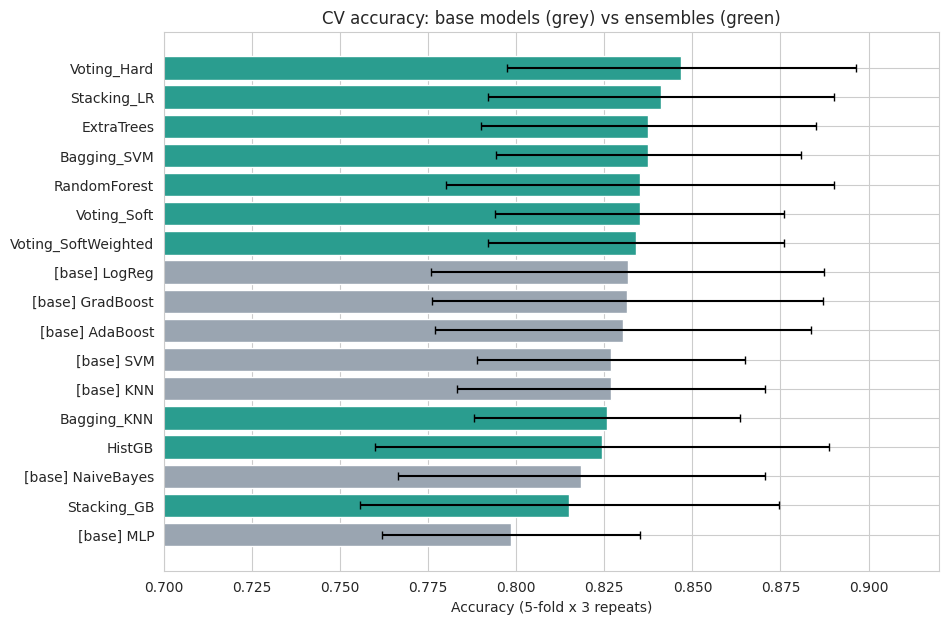

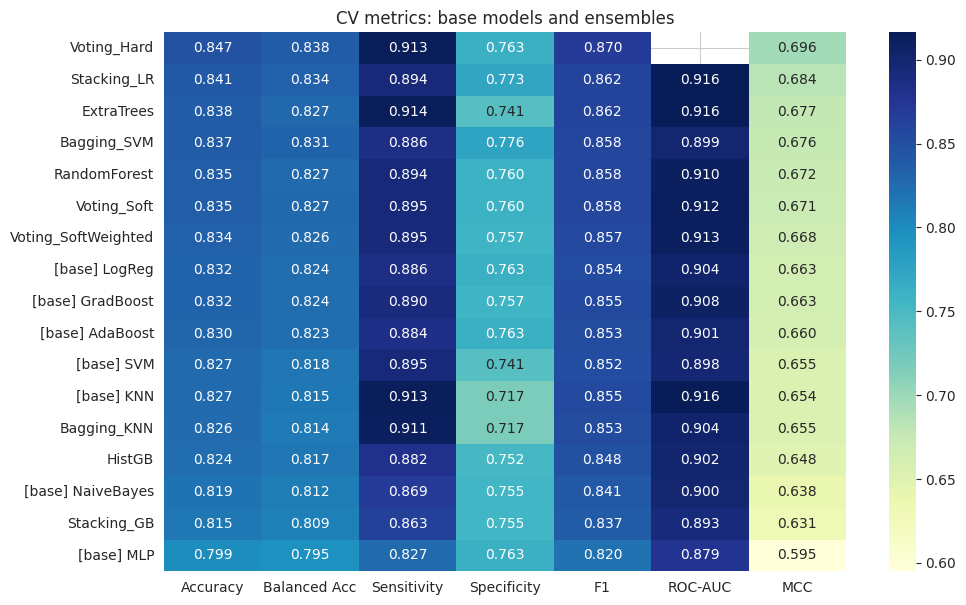

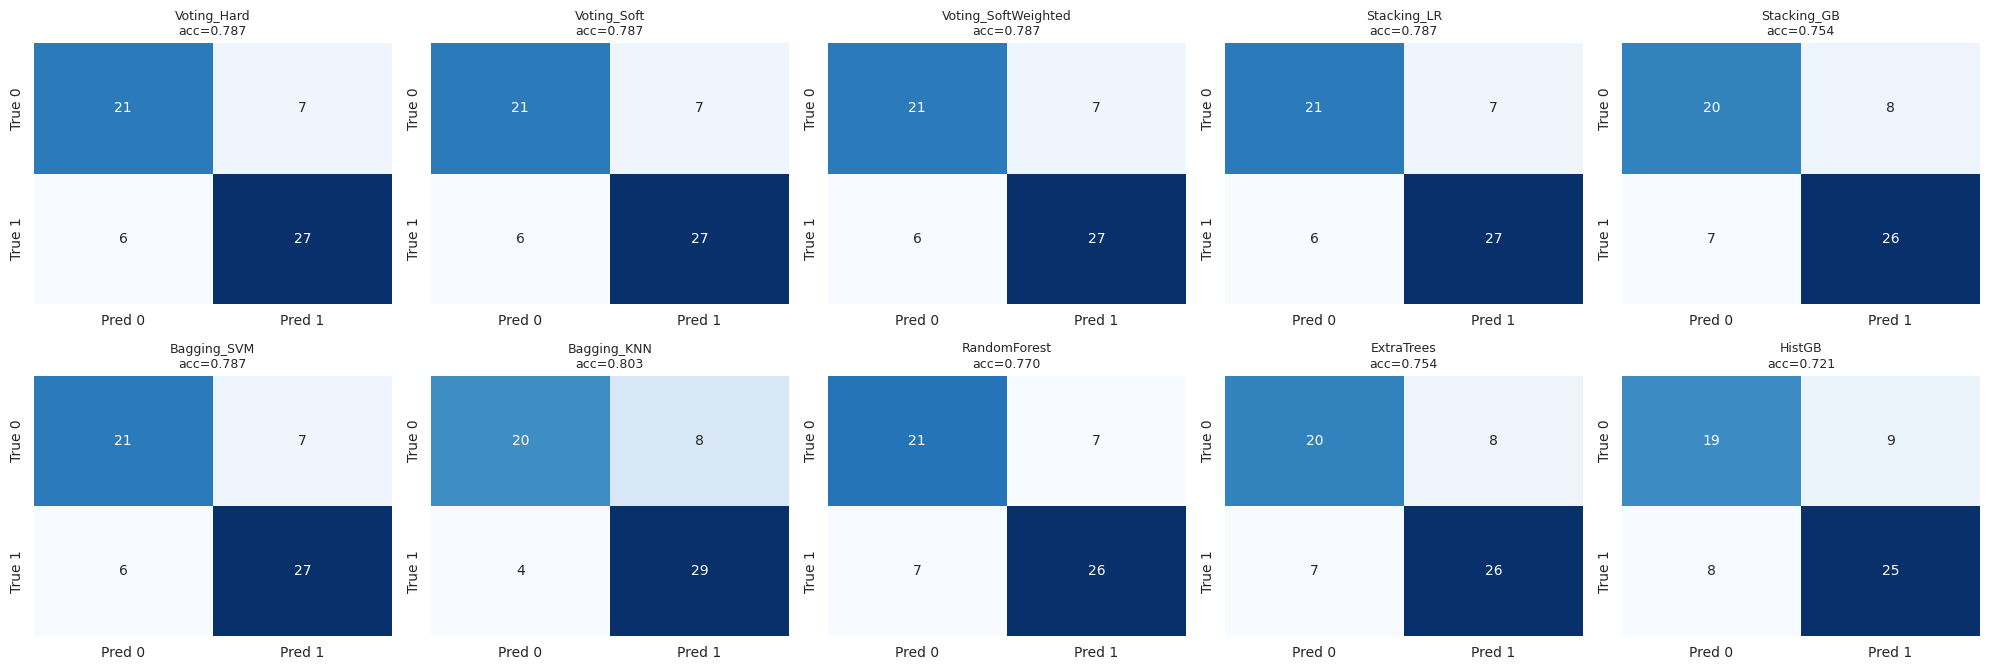

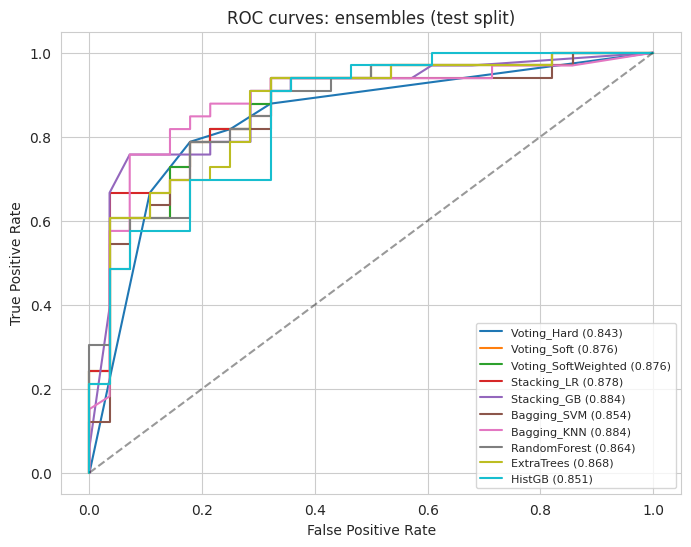

In [ ]:
metric_cols_cv = ["Accuracy", "Balanced Acc", "Sensitivity", "Specificity", "F1", "ROC-AUC"]

# 1) Accuracy with error bars: base models vs ensembles
plot_df = cv_table.sort_values("Accuracy")
colors = ["#9aa5b1" if n.startswith("[base]") else "#2a9d8f" for n in plot_df.index]
plt.figure(figsize=(10, 7))
plt.barh(plot_df.index, plot_df["Accuracy"], xerr=plot_df["Acc std"], color=colors, capsize=3)
plt.xlim(0.7, 0.92)
plt.title("CV accuracy: base models (grey) vs ensembles (green)")
plt.xlabel("Accuracy (5-fold x 3 repeats)")
plt.show()

# 2) Metric heatmap
plt.figure(figsize=(11, 7))
sns.heatmap(cv_table[metric_cols_cv + ["MCC"]].astype(float), annot=True, fmt=".3f", cmap="YlGnBu")
plt.title("CV metrics: base models and ensembles")
plt.show()

# 3) Confusion matrices (test split) for ensembles
ncols = 5
nrows = int(np.ceil(len(ens_names) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3.4 * nrows))
for ax, n in zip(axes.ravel(), ens_names):
    p, _ = test_preds[n]
    sns.heatmap(confusion_matrix(y_test, p, labels=[0, 1]), annot=True, fmt="d", cmap="Blues",
                cbar=False, ax=ax, xticklabels=["Pred 0", "Pred 1"], yticklabels=["True 0", "True 1"])
    ax.set_title(f"{n}\nacc={accuracy_score(y_test, p):.3f}", fontsize=9)
for ax in axes.ravel()[len(ens_names):]:
    ax.axis("off")
plt.tight_layout()
plt.show()

# 4) ROC curves (test split)
plt.figure(figsize=(8, 6))
for n in ens_names:
    _, pr = test_preds[n]
    fpr, tpr, _ = roc_curve(y_test, pr)
    plt.plot(fpr, tpr, label=f"{n} ({roc_auc_score(y_test, pr):.3f})")
plt.plot([0, 1], [0, 1], "k--", alpha=0.4)
plt.xlabel("False Positive Rate"); plt.ylabel("True Positive Rate")
plt.title("ROC curves: ensembles (test split)")
plt.legend(fontsize=8)
plt.show()

**Cell E8: Why an ensemble helps (or doesn’t): error diversity**

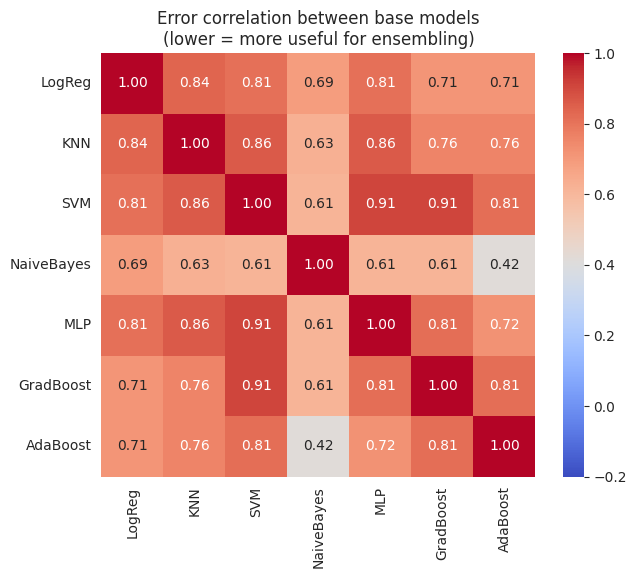

Samples every base model got wrong : 7
Samples at least one model got right: 54 / 61


In [ ]:
err = pd.DataFrame({n: (test_preds[n][0] != y_test.values).astype(int) for n in BASE_NAMES})

plt.figure(figsize=(7, 5.5))
sns.heatmap(err.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-0.2, vmax=1)
plt.title("Error correlation between base models\n(lower = more useful for ensembling)")
plt.show()

print("Samples every base model got wrong :", int((err.sum(axis=1) == len(BASE_NAMES)).sum()))
print("Samples at least one model got right:", int((err.sum(axis=1) < len(BASE_NAMES)).sum()), "/", len(err))

**Cell E9 (optional): Blend the Keras NN with the soft-voting ensemble**

In [ ]:
pr_soft = test_preds["Voting_Soft"][1]
for w in [0.0, 0.25, 0.5, 0.75, 1.0]:
    pr = (1 - w) * pr_soft + w * y_proba_nn
    pred = (pr >= 0.5).astype(int)
    print(f"NN weight {w:.2f}: acc={accuracy_score(y_test, pred):.4f}  "
          f"auc={roc_auc_score(y_test, pr):.4f}  sens={recall_score(y_test, pred):.4f}")

# Keep one blend in the results dict (equal weights)
pr_blend = 0.5 * pr_soft + 0.5 * y_proba_nn
test_preds["Soft+NN"] = ((pr_blend >= 0.5).astype(int), pr_blend)

NN weight 0.00: acc=0.7869  auc=0.8755  sens=0.8182
NN weight 0.25: acc=0.7869  auc=0.8799  sens=0.8182
NN weight 0.50: acc=0.7869  auc=0.8799  sens=0.8182
NN weight 0.75: acc=0.7705  auc=0.8723  sens=0.8182
NN weight 1.00: acc=0.6230  auc=0.7684  sens=0.9091
